In [33]:
from __future__ import annotations
import re
import operator
from typing import TypedDict, List, Annotated
from pathlib import Path

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
load_dotenv()

True

In [26]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description='What to cover')

In [27]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [28]:
class State(TypedDict):
    topic: str
    plan: Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str], operator.add]
    final: str

In [29]:
llm = ChatGroq(model='openai/gpt-oss-120b')

In [30]:
def orchestrator(state: State) -> dict:

    llm_plan_structured = llm.with_structured_output(Plan)
    plan = llm_plan_structured.invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )
    return {"plan": plan}

In [31]:
def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]})
            for task in state["plan"].tasks]

In [32]:
def worker(payload: dict) -> dict:

    # payload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [34]:
def sanitize_filename(title: str) -> str:
    name = title.strip()
    name = re.sub(r'[\\/:*?"<>|]', '_', name)  # kill all Windows-forbidden chars
    name = re.sub(r'\s+', '_', name)            # spaces → underscore
    name = re.sub(r'_+', '_', name)             # collapse duplicate underscores
    name = name.strip('_.')                      # clean edges
    name = name.lower()
    return name[:200]                            # stay under FS limit

In [35]:
def reducer(state: State) -> dict:
    
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title}\n\n{body}\n"

    # ---- save to file ----
    output_dir = Path("output")  # Create output folder
    output_dir.mkdir(exist_ok=True)

    safe_name  = sanitize_filename(title)          # ← KEY FIX: sanitize before use
    # ---- save to file ----
    filename = f"1-sbw_{safe_name}.md"
    output_path = output_dir / filename
    output_path.write_text(final_md, encoding="utf-8")
    print(f"Blog saved to: {output_path.resolve()}")

    return {"final": final_md}

In [36]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

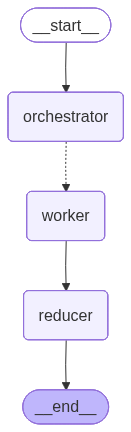

In [37]:
g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()

app

In [38]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []})

Blog saved to: S:\Coding\Blog_Writing_Agent\output\1-sbw_demystifying_self-attention_how_transformers_see_the_world.md


In [39]:
out

{'topic': 'Write a blog on Self Attention',
 'plan': Plan(blog_title='Demystifying Self-Attention: How Transformers See the World', tasks=[Task(id=1, title='Introduction to Attention Mechanisms', brief='Explain the motivation behind attention, contrast with traditional sequence models, and set the stage for self-attention.'), Task(id=2, title='The Core Idea of Self-Attention', brief='Define self-attention, describe query‑key‑value formulation, and illustrate with a simple example.'), Task(id=3, title='Mathematical Formulation and Computation', brief='Walk through the matrix operations (Q, K, V, scaling, softmax), discuss computational complexity, and show a step‑by‑step calculation.'), Task(id=4, title='Multi‑Head Self-Attention', brief='Explain why multiple heads are useful, how they are implemented, and the benefits of capturing diverse relationships.'), Task(id=5, title='Positional Encoding and Order Awareness', brief='Describe how Transformers inject sequence order using sinusoidal